# Projet AT&T : Détecteur de spams SMS

**Contexte et objectif**  
AT&T souhaite protéger ses utilisateurs des SMS indésirables. Les spams sont
aujourd'hui signalés manuellement ; l'objectif est de **les détecter
automatiquement à partir du seul contenu du message**.

Il s'agit d'un problème de **classification binaire de texte** (donnée non
structurée) : un SMS est soit `ham` (légitime), soit `spam`.


**Etapes du projet** 
1. Imports et configuration
2. Exploration et préparation des données
3. Baseline : TF-IDF + régression logistique
4. Réseaux de neurones
5. Comparaison des modèles
6. Analyse des erreurs
7. Démonstration d'inférence
8. Sauvegarde des résultats

**Méthodologie**
1. Charger les données, **contrôler leur qualité** (doublons) et les explorer.
2. Transformer le texte en matrices exploitables par un réseau de neurones.
3. Découper en **trois jeux** : entraînement, validation (pour régler et
   arrêter l'entraînement), test (évaluation finale, jamais utilisé avant).
4. Comparer quatre modèles, du plus simple au plus sophistiqué :
   - **TF-IDF + régression logistique** : baseline non neuronale ;
   - **réseau dense** (perceptron multicouche) sur embeddings moyennés ;
   - **LSTM bidirectionnel** (réseau récurrent) ;
   - **DistilBERT** pré-entraîné, affiné par *transfer learning*.
5. Évaluer sur train / validation / test, analyser les erreurs, conclure.

**Choix de la métrique**  
Seuls ~13 % des messages sont des spams : un modèle qui répond toujours `ham`
obtiendrait ~87 % d'*accuracy* sans rien détecter. On suit donc surtout la
**précision** (parmi les messages signalés, combien sont vraiment des spams),
le **rappel** (parmi les spams, combien sont détectés), le **F1** (leur
compromis) et la **PR-AUC** (qualité du score indépendamment du seuil).

## 1. Imports et configuration

In [2]:
import copy
import json
import random
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, TensorDataset
from transformers import DistilBertForSequenceClassification
from transformers import DistilBertTokenizerFast

c:\Users\DeatHunter\anaconda3\envs\cdsd_b4_att_spam_detector\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Paramètres
SEED = 42
TEST_SIZE = 0.15          # part du jeu de test
VAL_SIZE = 0.15           # part du jeu de validation
MIN_FREQ = 2              # fréquence minimale d'un mot (vocabulaire)
BATCH_SIZE = 32
MAX_EPOCHS = 30           # plafond ; l'arrêt anticipé stoppe avant en pratique
PATIENCE = 3              # epochs sans amélioration avant arrêt anticipé
THRESHOLD = 0.5           # seuil de décision spam / ham
BERT_NAME = "distilbert-base-uncased"

# Chemins relatifs
DATA_PATH = Path("../data/spam.csv")
IMAGES_DIR = Path("../assets/images")
RESULTS_DIR = Path("../results")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid")


def set_seed(seed=SEED):
    """Fixe les graines aléatoires pour des résultats reproductibles."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print(f"Device utilisé : {DEVICE}")

Device utilisé : cpu


## 2. Exploration et préparation des données

Le fichier est encodé en `latin-1` et contient trois colonnes parasites
(presque vides) que l'on ignore. On conserve uniquement l'étiquette (`v1`) et
le texte (`v2`).

**Point d'attention : les doublons.** Ce jeu de données contient des messages
strictement identiques. S'ils sont répartis à la fois dans le jeu
d'entraînement et dans le jeu de test, le modèle est évalué sur des messages
qu'il a déjà vus et les scores sont **artificiellement gonflés**. On les
supprime donc avant tout découpage.

In [4]:
raw = pd.read_csv(DATA_PATH, encoding="latin-1")[["v1", "v2"]]
raw = raw.rename(columns={"v1": "label", "v2": "text"})

print(f"SMS chargés : {len(raw)}")
print(f"Valeurs manquantes : {int(raw.isna().sum().sum())}")
print(f"Doublons (texte identique) : {int(raw.duplicated('text').sum())}")

df = raw.drop_duplicates(subset="text").reset_index(drop=True)
df["target"] = (df["label"] == "spam").astype(int)

print(f"\nSMS après suppression des doublons : {len(df)}")
print(df["label"].value_counts().to_string())
print(f"Part de spams : {df['target'].mean():.1%}")
df.head()

SMS chargés : 5572
Valeurs manquantes : 0
Doublons (texte identique) : 403

SMS après suppression des doublons : 5169
label
ham     4516
spam     653
Part de spams : 12.6%


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 2.1 Analyse exploratoire

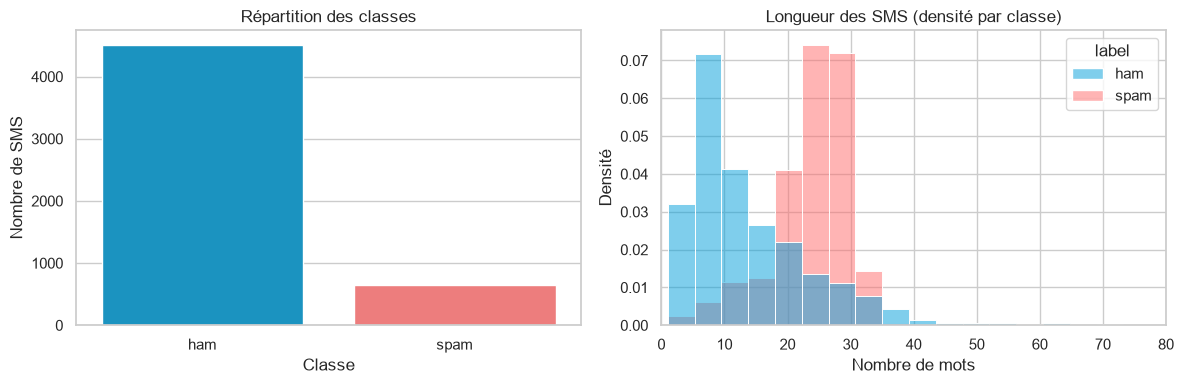

label
ham     14.1
spam    23.7


In [5]:
df["nb_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="label", hue="label", order=["ham", "spam"],
              palette=["#009FDB", "#FF6B6B"], legend=False, ax=axes[0])
axes[0].set_title("Répartition des classes")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Nombre de SMS")

sns.histplot(data=df, x="nb_words", hue="label", hue_order=["ham", "spam"],
             palette=["#009FDB", "#FF6B6B"], bins=40, stat="density",
             common_norm=False, ax=axes[1])
axes[1].set_title("Longueur des SMS (densité par classe)")
axes[1].set_xlabel("Nombre de mots")
axes[1].set_ylabel("Densité")
axes[1].set_xlim(0, 80)   # la queue (jusqu'à 170 mots) écraserait le graphe

plt.tight_layout()
plt.savefig(IMAGES_DIR / "01_eda_classes_longueur.png", dpi=150,
            bbox_inches="tight")
plt.show()

print(df.groupby("label")["nb_words"].mean().round(1).to_string())

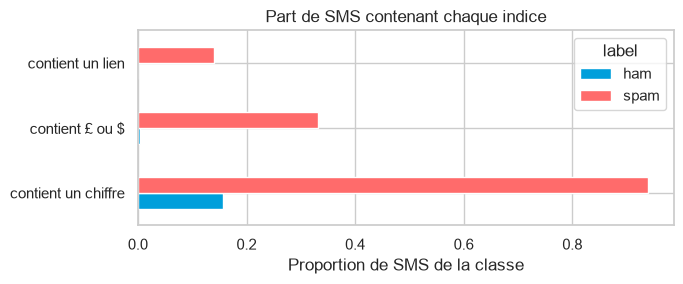

label,ham,spam
contient un chiffre,0.157,0.940
contient £ ou $,0.004,0.332
contient un lien,0.000,0.139


In [6]:
# Certains indices simples distinguent-ils déjà les deux classes ?
signals = pd.DataFrame({
    "contient un chiffre": df["text"].str.contains(r"\d"),
    "contient £ ou $": df["text"].str.contains(r"[£$]"),
    "contient un lien": df["text"].str.contains(r"http|www", case=False),
})
share = signals.groupby(df["label"]).mean().T[["ham", "spam"]]

ax = share.plot.barh(color=["#009FDB", "#FF6B6B"], figsize=(7, 3))
ax.set_title("Part de SMS contenant chaque indice")
ax.set_xlabel("Proportion de SMS de la classe")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "02_eda_indices.png", dpi=150, bbox_inches="tight")
plt.show()
share.round(3)

**Observations :**
- les classes sont déséquilibrées (~13 % de spams) : il faudra le compenser à
  l'entraînement et choisir des métriques adaptées ;
- les spams sont nettement plus longs que les messages légitimes ;
- les **chiffres** (numéros, montants, codes) et les symboles monétaires sont
  des signaux très forts. Notre prétraitement ne doit donc **pas** les
  supprimer, contrairement à un nettoyage « lettres uniquement ».

### 2.2 Prétraitement du texte

Le nettoyage reste volontairement simple :
- passage en minuscules ;
- remplacement des liens par le jeton `<url>` et de toute suite de chiffres
  par le jeton `<num>` : on garde l'information « il y a un nombre / un lien »
  sans multiplier les mots rares (chaque numéro de téléphone est unique) ;
- conservation des symboles `£`, `$` et `!`, utiles pour détecter un spam ;
- découpage en mots (tokens) séparés par des espaces.

DistilBERT, lui, reçoit le texte brut : son propre *tokenizer* gère déjà la
ponctuation et les majuscules.

In [7]:
URL_PATTERN = re.compile(r"(https?://\S+|www\.\S+)")
NUM_PATTERN = re.compile(r"\d+")
TOKEN_PATTERN = re.compile(r"<url>|<num>|[a-z']+|[£$!]")


def clean_text(text):
    """Normalise un SMS : minuscules, jetons <url>/<num>, mots, symboles."""
    text = text.lower()
    text = URL_PATTERN.sub(" <url> ", text)
    text = NUM_PATTERN.sub(" <num> ", text)
    return " ".join(TOKEN_PATTERN.findall(text))


df["clean_text"] = df["text"].apply(clean_text)

for text in df.loc[df["target"] == 1, "text"].head(3):
    print("AVANT :", text)
    print("APRÈS :", clean_text(text), "\n")
print(f"Messages vides après nettoyage : {(df['clean_text'] == '').sum()}")

AVANT : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
APRÈS : free entry in <num> a wkly comp to win fa cup final tkts <num> st may <num> text fa to <num> to receive entry question std txt rate t c's apply <num> over <num> 's 

AVANT : FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv
APRÈS : freemsg hey there darling it's been <num> week's now and no word back ! i'd like some fun you up for it still tb ok ! xxx std chgs to send £ <num> <num> to rcv 

AVANT : WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
APRÈS : winner ! ! as a valued network customer you have been selected to receivea £ <num> prize reward ! to claim call <num> claim code kl <num> valid <num> hours only

### 2.3 Découpage train / validation / test

Découpage **stratifié** (même proportion de spams dans chaque jeu) :
- **train** (70 %) : apprentissage des paramètres ;
- **validation** (15 %) : suivi de l'entraînement, arrêt anticipé, choix du
  meilleur modèle ;
- **test** (15 %) : évaluation finale, jamais utilisé pour choisir ou régler un modèle

In [8]:
train_val_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["target"], random_state=SEED
)
train_df, val_df = train_test_split(
    train_val_df,
    test_size=VAL_SIZE / (1 - TEST_SIZE),
    stratify=train_val_df["target"],
    random_state=SEED,
)

splits = {"train": train_df, "val": val_df, "test": test_df}
labels = {name: part["target"].to_numpy() for name, part in splits.items()}

summary = pd.DataFrame({
    "SMS": {name: len(part) for name, part in splits.items()},
    "spams": {name: int(part["target"].sum())
              for name, part in splits.items()},
    "part de spams": {name: f"{part['target'].mean():.1%}"
                      for name, part in splits.items()},
})
summary

,SMS,spams,part de spams
train,3617,457,12.6%
val,776,98,12.6%
test,776,98,12.6%


### 2.4 Outils d'évaluation

Quelques fonctions réutilisées pour **tous** les modèles, afin que la
comparaison soit équitable : mêmes métriques, mêmes jeux, même seuil.

In [9]:
results = {}     # métriques par modèle et par jeu
probas = {}      # probabilités de spam par modèle et par jeu
histories = {}   # courbes de loss des modèles neuronaux


def compute_metrics(y_true, proba, threshold=THRESHOLD):
    """Calcule les métriques de classification à partir des probabilités."""
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred)),
        "f1": float(f1_score(y_true, pred)),
        "pr_auc": float(average_precision_score(y_true, proba)),
    }


def register_model(name, split_probas, inference_seconds):
    """Enregistre les probabilités et métriques d'un modèle sur 3 jeux."""
    probas[name] = split_probas
    results[name] = {
        split: compute_metrics(labels[split], proba)
        for split, proba in split_probas.items()
    }
    test_pred = (split_probas["test"] >= THRESHOLD).astype(int)
    results[name]["test_confusion_matrix"] = confusion_matrix(
        labels["test"], test_pred
    ).tolist()
    results[name]["ms_per_message"] = (
        1000 * inference_seconds / len(labels["test"])
    )
    row = results[name]
    print(f"{name} | F1 train {row['train']['f1']:.3f} "
          f"| val {row['val']['f1']:.3f} | test {row['test']['f1']:.3f}")

## 3. Baseline : TF-IDF + régression logistique

L'énoncé conseille de **commencer simple**. Cette baseline transforme chaque
message en vecteur **TF-IDF** (importance de chaque mot ou paire de mots,
pondérée par sa rareté dans le corpus) puis applique une régression
logistique. Elle sert de point de comparaison : un réseau de neurones n'a
d'intérêt que s'il fait mieux.

`class_weight="balanced"` pénalise davantage les erreurs sur la classe rare
(spam).

In [10]:
# token_pattern : on garde nos jetons (<num>, <url>, £, !) tels quels
tfidf = TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(train_df["clean_text"])

logreg = LogisticRegression(class_weight="balanced", max_iter=1000)
logreg.fit(X_train_tfidf, labels["train"])


def logreg_proba(texts):
    """Probabilité de spam pour une liste de textes déjà nettoyés."""
    return logreg.predict_proba(tfidf.transform(texts))[:, 1]


split_probas = {
    split: logreg_proba(part["clean_text"])
    for split, part in splits.items() if split != "test"
}
start = time.perf_counter()
split_probas["test"] = logreg_proba(test_df["clean_text"])
elapsed = time.perf_counter() - start

register_model("TF-IDF + LogReg", split_probas, elapsed)

TF-IDF + LogReg | F1 train 0.970 | val 0.925 | test 0.915


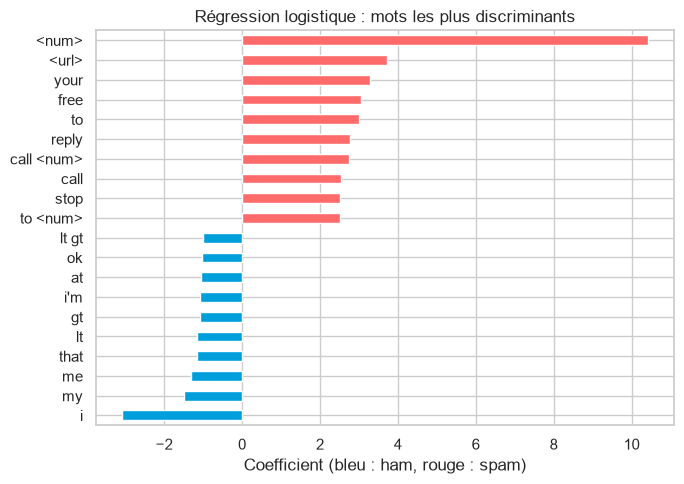

In [11]:
# Interprétabilité : mots qui poussent le plus vers « spam » ou « ham »
coefs = pd.Series(logreg.coef_[0], index=tfidf.get_feature_names_out())
top = pd.concat([coefs.nsmallest(10), coefs.nlargest(10)]).sort_values()

colors = ["#FF6B6B" if value > 0 else "#009FDB" for value in top]
ax = top.plot.barh(color=colors, figsize=(7, 5))
ax.set_title("Régression logistique : mots les plus discriminants")
ax.set_xlabel("Coefficient (bleu : ham, rouge : spam)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "03_baseline_coefficients.png", dpi=150,
            bbox_inches="tight")
plt.show()

## 4. Réseaux de neurones

### 4.1 Préparation des données

Un réseau ne lit pas du texte : il faut le convertir en **matrices de
nombres**.

1. **Vocabulaire** : chaque mot présent au moins `MIN_FREQ` fois dans le jeu
   d'entraînement reçoit un identifiant entier. Les autres deviennent `<unk>`.
   Le vocabulaire est construit **uniquement sur le train** pour ne pas
   « fuiter » d'information du test.
2. **Séquences de longueur fixe** : chaque message devient une suite
   d'identifiants, tronquée ou complétée par des `<pad>` (identifiant 0). La
   longueur est choisie d'après les données (99ᵉ percentile), pas au hasard.
3. **Tenseurs** : ces suites sont regroupées en matrices (`n_messages ×
   longueur`) servies au réseau par paquets (*batchs*).

In [12]:
PAD, UNK = 0, 1

token_counts = Counter(
    token for text in train_df["clean_text"] for token in text.split()
)
vocab = {"<pad>": PAD, "<unk>": UNK}
for token, count in token_counts.most_common():
    if count >= MIN_FREQ:
        vocab[token] = len(vocab)

train_lengths = train_df["clean_text"].str.split().str.len()
MAX_LEN = int(np.percentile(train_lengths, 99))

val_tokens = [t for text in val_df["clean_text"] for t in text.split()]
coverage = np.mean([t in vocab for t in val_tokens])
print(f"Taille du vocabulaire        : {len(vocab)}")
print(f"Longueur des séquences       : {MAX_LEN} mots (99e percentile)")
print(f"Mots de validation connus    : {coverage:.1%}")


def encode(text, max_len=MAX_LEN):
    """Convertit un texte nettoyé en liste d'identifiants de longueur fixe."""
    ids = [vocab.get(token, UNK) for token in text.split()][:max_len]
    return ids + [PAD] * (max_len - len(ids))


def make_loaders(tensors, batch_size=BATCH_SIZE):
    """Construit les DataLoaders à partir de tenseurs (entrées..., labels).

    `train_fit` est mélangé (pour apprendre) ; `train` ne l'est pas (pour
    évaluer le modèle sur le jeu d'entraînement dans l'ordre).
    """
    datasets = {name: TensorDataset(*data) for name, data in tensors.items()}
    loaders = {name: DataLoader(ds, batch_size=batch_size)
               for name, ds in datasets.items()}
    loaders["train_fit"] = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True
    )
    return loaders


def labels_tensor(part):
    return torch.tensor(part["target"].to_numpy(), dtype=torch.float32)


seq_tensors = {
    name: (
        torch.tensor([encode(t) for t in part["clean_text"]],
                     dtype=torch.long),
        labels_tensor(part),
    )
    for name, part in splits.items()
}
seq_loaders = make_loaders(seq_tensors)
print(f"Forme du jeu d'entraînement  : {tuple(seq_tensors['train'][0].shape)}")

Taille du vocabulaire        : 2973
Longueur des séquences       : 54 mots (99e percentile)
Mots de validation connus    : 91.4%
Forme du jeu d'entraînement  : (3617, 54)


### 4.2 Boucle d'entraînement commune

Les trois modèles neuronaux partagent la **même** boucle et la **même**
fonction de coût, ce qui rend leur comparaison équitable.

- **Fonction de coût** : entropie croisée binaire (`BCEWithLogitsLoss`) avec
  `pos_weight` = nombre de ham / nombre de spams (6,91). Une erreur sur un
  spam compte 6,91 fois plus qu'une erreur sur un ham : cela compense le
  déséquilibre des classes.
- **Optimiseur** : AdamW.
- **Arrêt anticipé** (*early stopping*) : on suit la loss sur le jeu de
  **validation** et on arrête si elle ne s'améliore plus pendant `PATIENCE`
  epochs. On restaure alors les poids de la **meilleure** epoch. Cela limite
  le **surapprentissage** (le modèle apprend le train par cœur et généralise
  mal).

In [13]:
n_ham = int((labels["train"] == 0).sum())
n_spam = int((labels["train"] == 1).sum())
pos_weight = torch.tensor(n_ham / n_spam, dtype=torch.float32, device=DEVICE)
print(f"pos_weight = {pos_weight.item():.2f}")


def run_epoch(model, loader, criterion, optimizer=None):
    """Parcourt un jeu de données ; entraîne si un optimiseur est fourni."""
    training = optimizer is not None
    model.train(training)
    total_loss, n_samples = 0.0, 0
    with torch.set_grad_enabled(training):
        for *inputs, y in loader:
            inputs = [tensor.to(DEVICE) for tensor in inputs]
            y = y.to(DEVICE)
            loss = criterion(model(*inputs), y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(y)
            n_samples += len(y)
    return total_loss / n_samples


def train_model(model, loaders, criterion, optimizer, max_epochs,
                patience=PATIENCE):
    """Entraîne avec arrêt anticipé sur la loss de validation."""
    history = {"train_loss": [], "val_loss": []}
    best_val_loss, best_state, wait = float("inf"), None, 0
    for epoch in range(1, max_epochs + 1):
        train_loss = run_epoch(model, loaders["train_fit"], criterion,
                               optimizer)
        val_loss = run_epoch(model, loaders["val"], criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Epoch {epoch:2d} | train {train_loss:.4f} "
              f"| val {val_loss:.4f}")
        if val_loss < best_val_loss:
            best_val_loss, wait = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                print(f"Arrêt anticipé (meilleure epoch : {epoch - wait})")
                break
    model.load_state_dict(best_state)
    history["best_epoch"] = int(np.argmin(history["val_loss"])) + 1
    return history


@torch.no_grad()
def predict_proba(model, loader):
    """Probabilités de spam prédites pour tout un DataLoader."""
    model.eval()
    outputs = []
    for *inputs, _ in loader:
        logits = model(*[tensor.to(DEVICE) for tensor in inputs])
        outputs.append(torch.sigmoid(logits).cpu())
    return torch.cat(outputs).numpy()


def train_and_evaluate(name, model, loaders, lr, max_epochs=MAX_EPOCHS):
    """Entraîne un modèle, puis l'évalue sur train, validation et test."""
    model = model.to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=lr)
    histories[name] = train_model(model, loaders, criterion, optimizer,
                                  max_epochs)

    split_probas = {s: predict_proba(model, loaders[s])
                    for s in ("train", "val")}
    start = time.perf_counter()   # temps indicatif, hors tokenisation
    split_probas["test"] = predict_proba(model, loaders["test"])
    elapsed = time.perf_counter() - start
    register_model(name, split_probas, elapsed)
    return model

pos_weight = 6.91


### 4.3 Réseau dense (perceptron multicouche)

Premier réseau « classique » :
1. une couche d'**embedding** associe à chaque mot un vecteur de nombres
   appris pendant l'entraînement (les mots proches par le sens ou l'usage
   tendent à avoir des vecteurs proches) ;
2. les vecteurs des mots du message sont **moyennés** (en ignorant le
   padding), ce qui donne un seul vecteur par message ;
3. deux couches denses produisent le score de spam.

Ce modèle ignore l'**ordre** des mots : c'est ce que le LSTM va ajouter.

In [14]:
class MeanPoolMLP(nn.Module):
    """Embedding + moyenne des mots + perceptron multicouche."""

    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        mask = (x != PAD).unsqueeze(-1).float()
        pooled = (self.embedding(x) * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1)
        return self.classifier(pooled).squeeze(-1)


set_seed()
mlp = train_and_evaluate("Réseau dense", MeanPoolMLP(len(vocab)),
                         seq_loaders, lr=1e-3)

Epoch  1 | train 0.8563 | val 0.5426
Epoch  2 | train 0.4271 | val 0.3912
Epoch  3 | train 0.3112 | val 0.3315
Epoch  4 | train 0.2509 | val 0.3251
Epoch  5 | train 0.2086 | val 0.2994
Epoch  6 | train 0.1704 | val 0.2980
Epoch  7 | train 0.1379 | val 0.2851
Epoch  8 | train 0.1164 | val 0.2842
Epoch  9 | train 0.0973 | val 0.3040
Epoch 10 | train 0.0730 | val 0.3061
Epoch 11 | train 0.0646 | val 0.3044
Arrêt anticipé (meilleure epoch : 8)
Réseau dense | F1 train 0.929 | val 0.866 | test 0.872


### 4.4 LSTM bidirectionnel (réseau récurrent)

Un **LSTM** lit le message mot après mot et garde en mémoire le contexte
(« *claim* » après « *call now to* » n'a pas le même poids qu'ailleurs).
Il est **bidirectionnel** : une lecture de gauche à droite et une de droite à
gauche, concaténées.

Deux soins particuliers par rapport à une version naïve :
- `pack_padded_sequence` indique au LSTM la **vraie longueur** de chaque
  message, pour qu'il ignore le padding ;
- la moyenne finale sur la séquence est calculée **uniquement sur les vrais
  mots**.

In [15]:
class BiLSTMClassifier(nn.Module):
    """Embedding + LSTM bidirectionnel + moyenne masquée + couche de sortie."""

    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True,
                            bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden_dim, 1)   # x2 : deux directions

    def forward(self, x):
        mask = x != PAD
        lengths = mask.sum(dim=1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.embedding(x), lengths,
                                      batch_first=True, enforce_sorted=False)
        output, _ = self.lstm(packed)
        output, _ = pad_packed_sequence(output, batch_first=True,
                                        total_length=x.size(1))
        mask = mask.unsqueeze(-1).float()
        pooled = (output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.fc(self.dropout(pooled)).squeeze(-1)


set_seed()
lstm = train_and_evaluate("LSTM bidirectionnel", BiLSTMClassifier(len(vocab)),
                          seq_loaders, lr=1e-3)

Epoch  1 | train 0.6463 | val 0.3624
Epoch  2 | train 0.3102 | val 0.3101
Epoch  3 | train 0.1964 | val 0.3143
Epoch  4 | train 0.1521 | val 0.2769
Epoch  5 | train 0.1104 | val 0.3222
Epoch  6 | train 0.0613 | val 0.3109
Epoch  7 | train 0.0284 | val 0.3882
Arrêt anticipé (meilleure epoch : 4)
LSTM bidirectionnel | F1 train 0.971 | val 0.928 | test 0.924


### 4.5 DistilBERT : transfer learning

Entraîner un réseau de zéro sur ~3 600 messages est limité. **DistilBERT** est
un modèle de langage déjà entraîné sur des millions de textes : il « comprend »
l'anglais. On le réutilise (*transfer learning*) en :

1. remplaçant sa tête de classification par une sortie à 1 neurone (spam) ;
2. **gelant** les embeddings et les 4 premières couches Transformer (qui
   contiennent des connaissances générales du langage) ;
3. n'**affinant** (*fine-tuning*) que les 2 dernières couches et la tête, avec
   un très petit pas d'apprentissage (`lr = 2e-5`).

Moins de paramètres à entraîner = apprentissage plus rapide et moins de risque
de surapprentissage. Le premier lancement télécharge le modèle (connexion
Internet requise).

In [16]:
tokenizer = DistilBertTokenizerFast.from_pretrained(BERT_NAME)

bert_lengths = [len(ids) for ids in
                tokenizer(train_df["text"].tolist())["input_ids"]]
BERT_MAX_LEN = min(int(np.percentile(bert_lengths, 99)), 128)
print(f"Longueur max retenue (tokens DistilBERT) : {BERT_MAX_LEN}")


def encode_bert(part):
    """Tokenise les textes bruts : (input_ids, attention_mask, labels)."""
    enc = tokenizer(part["text"].tolist(), truncation=True,
                    padding="max_length", max_length=BERT_MAX_LEN,
                    return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], labels_tensor(part)


bert_loaders = make_loaders(
    {name: encode_bert(part) for name, part in splits.items()},
    batch_size=16,
)

Longueur max retenue (tokens DistilBERT) : 75


In [17]:
class DistilBertSpam(nn.Module):
    """DistilBERT pré-entraîné, avec gel des couches basses."""

    def __init__(self, name=BERT_NAME, n_frozen_layers=4):
        super().__init__()
        self.bert = DistilBertForSequenceClassification.from_pretrained(
            name, num_labels=1
        )
        frozen = [self.bert.distilbert.embeddings]
        layers = self.bert.distilbert.transformer.layer
        frozen += list(layers[:n_frozen_layers])
        for module in frozen:
            for param in module.parameters():
                param.requires_grad = False

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return output.logits.squeeze(-1)


set_seed()
bert_model = DistilBertSpam()
n_trainable = sum(p.numel() for p in bert_model.parameters()
                  if p.requires_grad)
n_total = sum(p.numel() for p in bert_model.parameters())
print(f"Paramètres entraînables : {n_trainable:,} / {n_total:,} "
      f"({n_trainable / n_total:.0%})")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3223.04it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Paramètres entraînables : 14,767,105 / 66,954,241 (22%)


In [ ]:
# Quelques epochs suffisent (ici, la meilleure est la 1re)
# (CPU : quelques minutes par epoch ; GPU : quelques secondes)
bert_model = train_and_evaluate("DistilBERT", bert_model, bert_loaders,
                                lr=2e-5, max_epochs=3)

Epoch  1 | train 0.3639 | val 0.2369
Epoch  2 | train 0.1722 | val 0.2651
Epoch  3 | train 0.1109 | val 0.3087
DistilBERT | F1 train 0.960 | val 0.942 | test 0.959


## 5. Comparaison des modèles

### 5.1 Courbes d'apprentissage

On compare la loss d'entraînement et de validation. Un écart qui se creuse
signale du surapprentissage ; la ligne pointillée marque l'epoch dont les
poids ont été conservés.

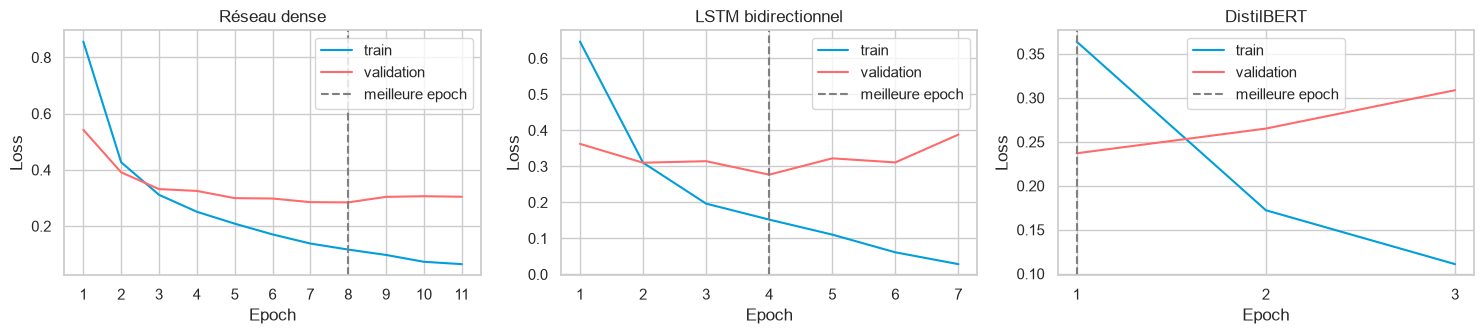

In [19]:
neural_models = list(histories)
fig, axes = plt.subplots(1, len(neural_models), squeeze=False,
                         figsize=(5 * len(neural_models), 3.5))
for ax, name in zip(axes[0], neural_models):
    hist = histories[name]
    epochs = range(1, len(hist["train_loss"]) + 1)
    ax.plot(epochs, hist["train_loss"], label="train", color="#009FDB")
    ax.plot(epochs, hist["val_loss"], label="validation", color="#FF6B6B")
    ax.axvline(hist["best_epoch"], ls="--", color="grey",
               label="meilleure epoch")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(list(epochs))
    ax.legend()
plt.tight_layout()
plt.savefig(IMAGES_DIR / "04_courbes_apprentissage.png", dpi=150,
            bbox_inches="tight")
plt.show()

### 5.2 Diagnostic du surapprentissage : train, validation, test

Si le F1 sur le train est bien supérieur à celui de validation, le modèle a
appris le jeu d'entraînement « par cœur ».

In [20]:
diagnostic = pd.DataFrame({
    name: {
        "F1 train": row["train"]["f1"],
        "F1 validation": row["val"]["f1"],
        "F1 test": row["test"]["f1"],
    }
    for name, row in results.items()
}).T
diagnostic["écart train - validation"] = (
    diagnostic["F1 train"] - diagnostic["F1 validation"]
)
diagnostic.round(3)

,F1 train,F1 validation,F1 test,écart train - validation
TF-IDF + LogReg,0.970,0.925,0.915,0.045
Réseau dense,0.929,0.866,0.872,0.063
LSTM bidirectionnel,0.971,0.928,0.924,0.044
DistilBERT,0.960,0.942,0.959,0.018


### 5.3 Résultats détaillés sur le jeu de test

,Accuracy,Précision (spam),Rappel (spam),F1 (spam),PR-AUC,ms / message
TF-IDF + LogReg,0.978,0.901,0.929,0.915,0.958,0.024
Réseau dense,0.965,0.814,0.939,0.872,0.962,0.016
LSTM bidirectionnel,0.981,0.919,0.929,0.924,0.968,0.219
DistilBERT,0.990,0.969,0.949,0.959,0.986,20.200


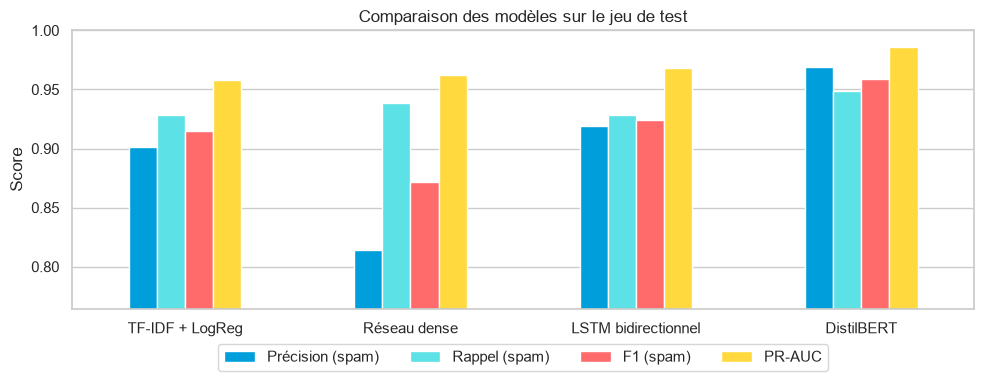

In [21]:
test_table = pd.DataFrame({
    name: {
        "Accuracy": row["test"]["accuracy"],
        "Précision (spam)": row["test"]["precision"],
        "Rappel (spam)": row["test"]["recall"],
        "F1 (spam)": row["test"]["f1"],
        "PR-AUC": row["test"]["pr_auc"],
        "ms / message": row["ms_per_message"],
    }
    for name, row in results.items()
}).T
display(test_table.round(3))

metrics_plot = test_table[["Précision (spam)", "Rappel (spam)", "F1 (spam)",
                           "PR-AUC"]]
ax = metrics_plot.plot.bar(rot=0, figsize=(10, 4),
                           color=["#009FDB", "#5CE1E6", "#FF6B6B", "#FFD93D"])
ax.set_ylim(max(0, metrics_plot.values.min() - 0.05), 1.0)
ax.set_title("Comparaison des modèles sur le jeu de test")
ax.set_ylabel("Score")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "05_comparaison_modeles.png", dpi=150,
            bbox_inches="tight")
plt.show()

### 5.4 Matrices de confusion (jeu de test)

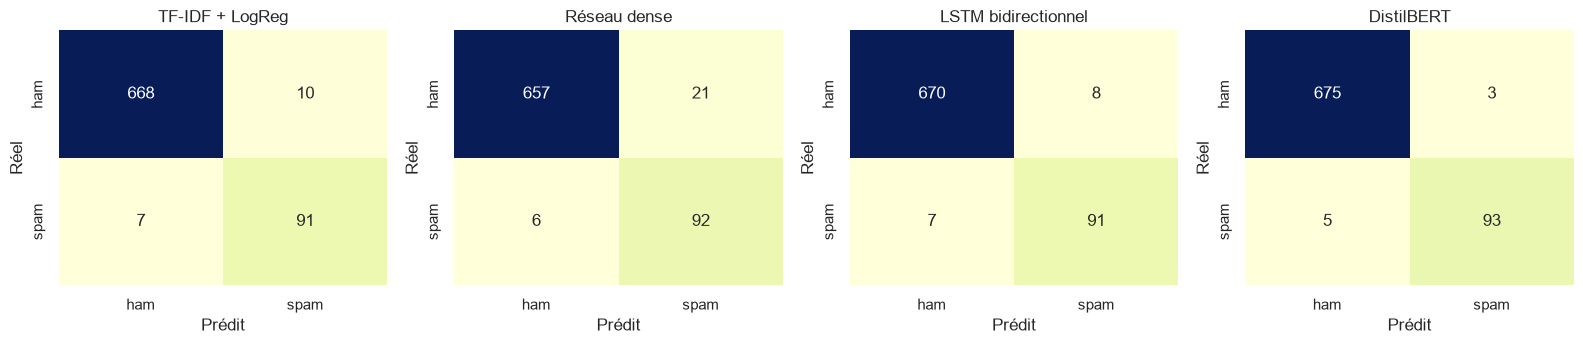

In [22]:
fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 3.6))
for ax, (name, row) in zip(axes, results.items()):
    sns.heatmap(np.array(row["test_confusion_matrix"]), annot=True, fmt="d",
                cmap="YlGnBu", cbar=False, ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    ax.set_title(name)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "06_matrices_confusion.png", dpi=150,
            bbox_inches="tight")
plt.show()

In [23]:
# Le meilleur modèle est choisi sur la VALIDATION (jamais sur le test)
best_name = max(results, key=lambda name: results[name]["val"]["f1"])
best = results[best_name]["test"]
base = results["TF-IDF + LogReg"]["test"]
n_test_spam = int(labels["test"].sum())

print(f"Meilleur modèle (F1 de validation) : {best_name}\n")
print("Performances annoncées sur le jeu de test (jamais vu) :")
print(f"  Accuracy  : {best['accuracy']:.1%}")
print(f"  Précision : {best['precision']:.1%}  "
      "(parmi les SMS signalés, part de vrais spams)")
print(f"  Rappel    : {best['recall']:.1%}  "
      f"(part des {n_test_spam} spams détectés)")
print(f"  F1        : {best['f1']:.3f}  "
      f"(baseline TF-IDF + LogReg : {base['f1']:.3f})")

Meilleur modèle (F1 de validation) : DistilBERT

Performances annoncées sur le jeu de test (jamais vu) :
  Accuracy  : 99.0%
  Précision : 96.9%  (parmi les SMS signalés, part de vrais spams)
  Rappel    : 94.9%  (part des 98 spams détectés)
  F1        : 0.959  (baseline TF-IDF + LogReg : 0.915)


**Lecture des résultats.** Le jeu de test ne contient qu'une centaine de
spams : un écart de quelques points de F1 correspond à **quelques messages**
seulement. Il faut donc comparer les modèles avec prudence et ne pas sur-
interpréter de petites différences. Le coût en temps d'inférence (colonne
`ms / message`) est aussi un critère de choix pour une mise en production.

## 6. Analyse des erreurs

Quels messages le meilleur modèle se trompe-t-il à classer ?
- **faux négatifs** : spams non détectés (l'utilisateur reçoit le spam) ;
- **faux positifs** : messages légitimes bloqués à tort (souvent plus grave
  pour un opérateur : un SMS important n'arrive pas).

In [24]:
errors = test_df.assign(proba=probas[best_name]["test"])
errors["pred"] = (errors["proba"] >= THRESHOLD).astype(int)
false_neg = errors[(errors["target"] == 1) & (errors["pred"] == 0)]
false_pos = errors[(errors["target"] == 0) & (errors["pred"] == 1)]
print(f"Modèle analysé : {best_name}")
print(f"Faux négatifs (spams manqués)    : {len(false_neg)}")
print(f"Faux positifs (ham bloqués)      : {len(false_pos)}\n")

with pd.option_context("display.max_colwidth", 110):
    print("Spams manqués :")
    display(false_neg[["text", "proba"]].round(3).head(8))
    print("Messages légitimes signalés à tort :")
    display(false_pos[["text", "proba"]].round(3).head(8))

Modèle analysé : DistilBERT
Faux négatifs (spams manqués)    : 5
Faux positifs (ham bloqués)      : 3

Spams manqués :


,text,proba
5062,"Latest News! Police station toilet stolen, cops have nothing to go on!",0.010
1414,Bought one ringtone and now getting texts costing 3 pound offering more tones etc,0.015
2302,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. ...,0.015
3888,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day,...",0.019
4109,RECPT 1/3. You have ordered a Ringtone. Your order is being processed...,0.007


Messages légitimes signalés à tort :


,text,proba
2561,Was playng 9 doors game and gt racing on phone lol,0.550
1313,Let Ur Heart Be Ur Compass Ur Mind Ur Map Ur Soul Ur Guide And U Will Never loose in world....gnun - Sent ...,0.872
3520,Plz note: if anyone calling from a mobile Co. &amp; asks u to type # &lt;#&gt; or # &lt;#&gt; . Do not do...,0.711


## 7. Démonstration d'inférence

Pour une utilisation réelle, chaque modèle doit pouvoir scorer un **nouveau
message brut** : on lui applique exactement le même prétraitement qu'à
l'entraînement.

In [25]:
@torch.no_grad()
def lstm_style_proba(model, texts):
    """Probabilités de spam pour les modèles à séquences d'identifiants."""
    model.eval()
    ids = [encode(clean_text(text)) for text in texts]
    x = torch.tensor(ids, dtype=torch.long, device=DEVICE)
    return torch.sigmoid(model(x)).cpu().numpy()


@torch.no_grad()
def bert_proba(model, texts):
    """Probabilités de spam pour DistilBERT à partir de textes bruts."""
    model.eval()
    enc = tokenizer(texts, truncation=True, padding=True,
                    max_length=BERT_MAX_LEN, return_tensors="pt").to(DEVICE)
    logits = model(enc["input_ids"], enc["attention_mask"])
    return torch.sigmoid(logits).cpu().numpy()


examples = [
    "Congratulations! You have won a £1000 prize. Call 09061701461 now!",
    "FREE entry to win tickets! Text WIN to 80086 now to claim",
    "Your parcel is waiting, pay the delivery fee at http://bit.ly/x1y2",
    "Hey, are we still on for dinner tonight at 8?",
    "I'll call you when I get out of the meeting",
]
demo = pd.DataFrame({
    "message": [text[:55] + "..." for text in examples],
    "TF-IDF + LogReg": logreg_proba([clean_text(t) for t in examples]),
    "Réseau dense": lstm_style_proba(mlp, examples),
    "LSTM bidirectionnel": lstm_style_proba(lstm, examples),
    "DistilBERT": bert_proba(bert_model, examples),
})
demo.set_index("message").round(3)

,TF-IDF + LogReg,Réseau dense,LSTM bidirectionnel,DistilBERT
message,,,,
Congratulations! You have won a £1000 prize. Call 09061...,0.970,0.999,0.991,0.997
FREE entry to win tickets! Text WIN to 80086 now to cla...,0.908,1.000,0.997,0.996
"Your parcel is waiting, pay the delivery fee at http://...",0.426,0.022,0.072,0.977
"Hey, are we still on for dinner tonight at 8?...",0.127,0.006,0.026,0.005
I'll call you when I get out of the meeting...,0.077,0.005,0.014,0.005


## 8. Sauvegarde des résultats

In [26]:
export = {
    "config": {
        "seed": SEED, "threshold": THRESHOLD, "min_freq": MIN_FREQ,
        "max_len": MAX_LEN, "bert_max_len": BERT_MAX_LEN,
        "pos_weight": round(pos_weight.item(), 2), "device": str(DEVICE),
    },
    "dataset": {
        "n_raw": len(raw), "n_after_dedup": len(df),
        "n_train": len(train_df), "n_val": len(val_df),
        "n_test": len(test_df), "n_test_spam": n_test_spam,
        "vocab_size": len(vocab),
    },
    "best_model_on_validation": best_name,
    "metrics": results,
    "histories": histories,
}
with open(RESULTS_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(export, file, indent=2, ensure_ascii=False)
print(f"Résultats écrits dans {RESULTS_DIR / 'metrics.json'}")

Résultats écrits dans ..\results\metrics.json


## Conclusion et limites 


**Ce qui a été réalisé.** Un détecteur de spams SMS complet : contrôle qualité
(suppression des doublons), prétraitement conservant les indices pertinents
(chiffres, symboles monétaires, liens), découpage train / validation / test,
puis comparaison équitable de quatre approches — de la baseline TF-IDF au
transfer learning avec DistilBERT, en passant par un réseau dense et un LSTM.

**Résultats obtenus (jeu de test : 776 SMS dont 98 spams, `SEED = 42`).**

| Modèle | Précision | Rappel | F1 | Erreurs (FP + FN) | ms / message (CPU) |
|---|---|---|---|---|---|
| TF-IDF + LogReg | 0,901 | 0,929 | 0,915 | 17 (10 + 7) | 0,024 |
| Réseau dense | 0,814 | 0,939 | 0,872 | 27 (21 + 6) | 0,016 |
| LSTM bidirectionnel | 0,919 | 0,929 | 0,924 | 15 (8 + 7) | 0,219 |
| **DistilBERT** | **0,969** | **0,949** | **0,959** | **8 (3 + 5)** | 20,200 |

- **DistilBERT** est le meilleur modèle, aussi bien sur la validation (choix du
  modèle) que sur le test : 93 spams détectés sur 98, 3 messages légitimes
  bloqués à tort. Il est aussi le seul à repérer l'exemple de SMS de livraison
  frauduleux de la démonstration (score 0,98 contre 0,02 à 0,43 pour les
  autres), ce qui suggère l'apport du pré-entraînement sur des formulations
  absentes du jeu d'entraînement.
- La **baseline TF-IDF** atteint un F1 de 0,915, très proche du LSTM (0,924) :
  un écart de 2 messages. Le réseau dense, lui, signale trop de faux positifs
  (précision 0,81).
- **Surapprentissage** : l'écart de F1 entre train et validation est de 0,04 à
  0,06 pour les autres modèles, et de 0,02 pour DistilBERT, dont le gel partiel
  limite le risque. Sa loss de validation remonte toutefois à partir de la 2ème epoch;
  la 1ère est la meilleure, on conserve donc les poids de cette epoch.
- **Coût** : DistilBERT est environ 840 fois plus lent que la baseline à
  l'inférence sur CPU (~5,6h de calcul sur un cœur pour 1 million de messages,
  contre ~24 s), ce qui impose un GPU ou un compromis en production.
- **Prudence statistique** : avec 98 spams, l'intervalle de confiance à 95 %
  du rappel est d'environ [89 %, 98 %] pour DistilBERT et [86 %, 97 %] pour la
  baseline. Ces intervalles se recouvrent : la supériorité de DistilBERT est
  plus marquée sur la précision, mais pas démontrée sur le rappel.
- **Erreurs** : les 5 spams manqués par DistilBERT ont des scores très bas
  (< 0,02) : un changement de seuil ne les récupérerait pas. Ce sont des
  spams sans marqueurs classiques (annonce « Police station toilet stolen »,
  sonneries, jeu-concours). Les 3 faux positifs ont des scores plus modérés
  (0,55 à 0,87) : message mentionnant un jeu, message en chaîne et alerte
  contre la fraude, qui ressemblent à de la publicité.

**Ce qu'il faut retenir.**
- Une baseline simple est déjà très performante sur ce corpus : le deep
  learning doit se juger sur ce qu'il apporte **en plus** (rappel, robustesse
  sur des formulations inédites) et à quel **coût** (temps d'entraînement et
  d'inférence, complexité).
- L'arrêt anticipé sur la validation et le diagnostic train / validation /
  test permettent de **détecter et limiter le surapprentissage**.
- Les choix techniques (pos_weight, pooling masqué, gel partiel de BERT)
  répondent chacun à un problème identifié : déséquilibre des classes,
  padding, petit jeu de données.

**Limites.**
- Jeu de données ancien, en anglais, de taille modeste : les spams actuels
  (hameçonnage par SMS, par exemple) diffèrent de ceux du corpus.
- Peu de spams dans le jeu de test : les écarts entre modèles sont à
  interpréter avec prudence.
- Un seul découpage et une seule graine : une validation croisée
  quantifierait l'incertitude.

**Perspectives.**
- Ajuster le **seuil de décision** selon le coût relatif d'un faux positif et
  d'un faux négatif, à partir de la courbe précision-rappel.
- **Augmenter** la classe spam avec des données synthétiques (réseaux
  génératifs adverses ou modèles de langage) pour pallier le déséquilibre.
- Surveiller en production la **dérive** des messages et ré-entraîner
  régulièrement ; étendre à d'autres langues.